# Customer Churn Analysis
Walkthrough of the data, what drives churn, and how the model performs.

Run `python src/train_model.py` first so the `outputs/` folder exists.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/telco_customer_churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality
`TotalCharges` loads as text because 11 rows are blank. Every one of them has `tenure = 0`, meaning they're brand-new customers who haven't been billed, so filling with 0 is the right fix (not the average).

In [2]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing = df[df['TotalCharges'].isna()]
print('Blank TotalCharges:', len(missing))
print('Tenure of those rows:', missing['tenure'].unique())
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['Churned'] = (df['Churn'] == 'Yes').astype(int)
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())
print(f"Churn rate: {df['Churned'].mean():.1%}")

Blank TotalCharges: 11
Tenure of those rows: [0]
Duplicate customer IDs: 0
Churn rate: 26.5%


## 2. What does churn look like?

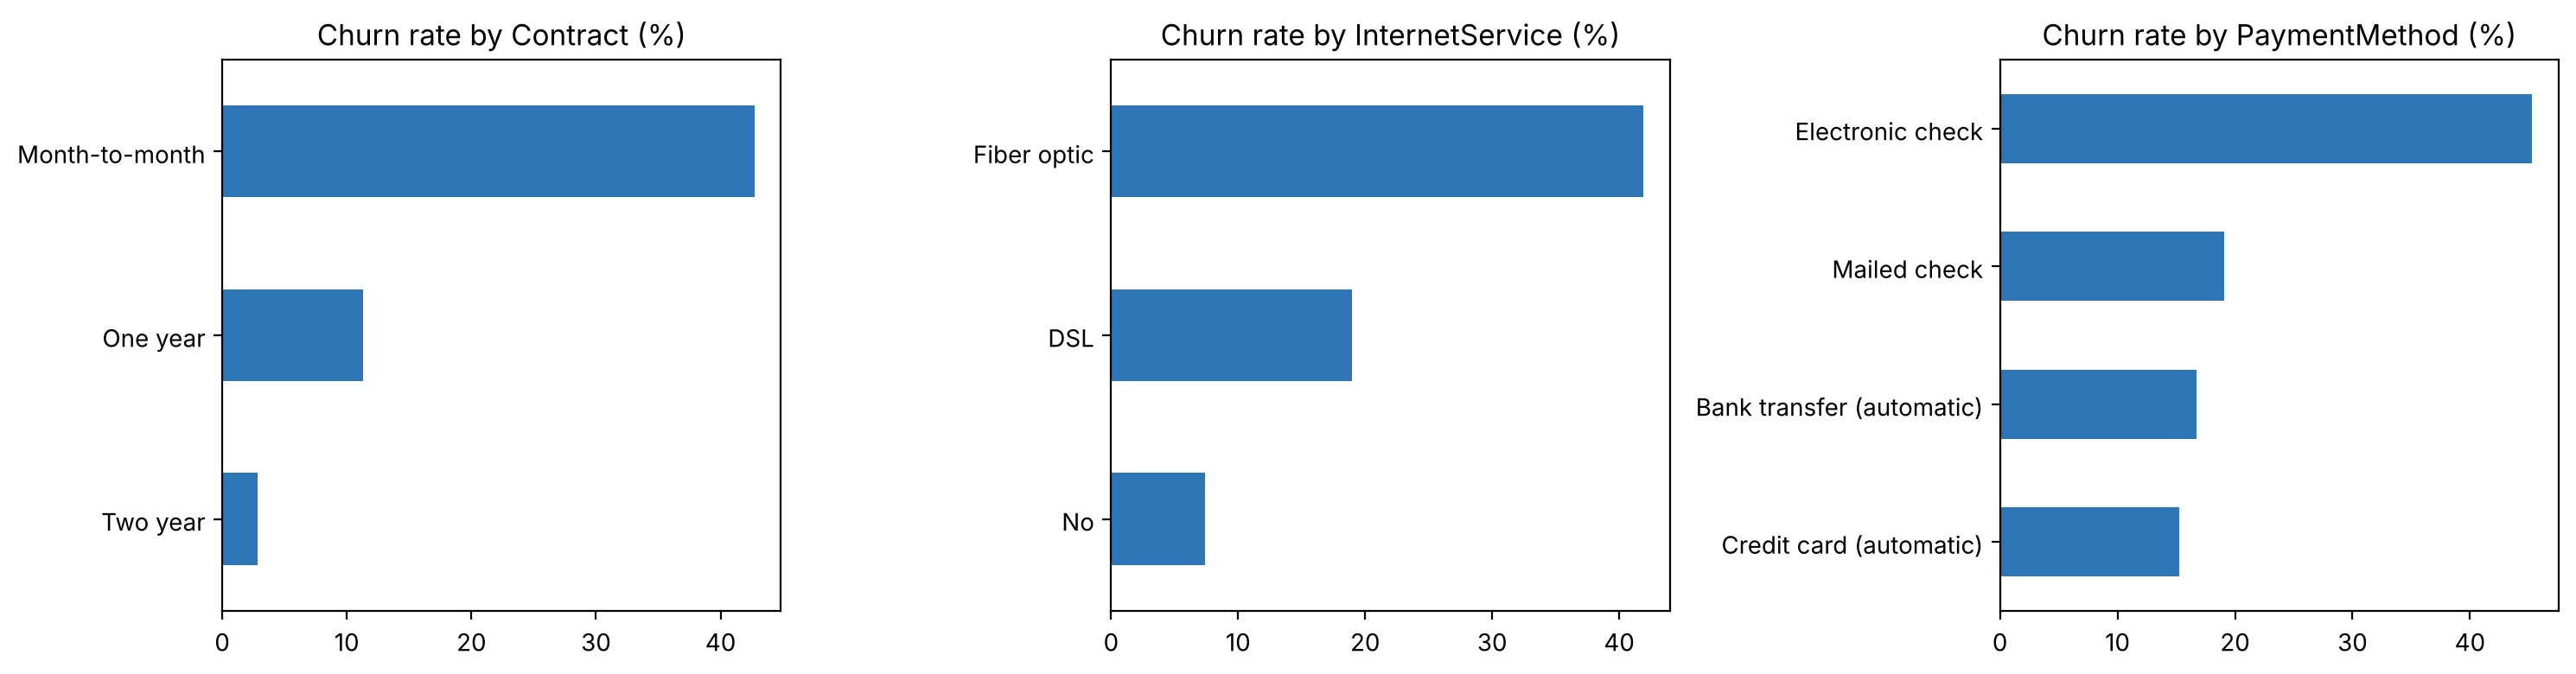

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    (df.groupby(col)['Churned'].mean() * 100).sort_values().plot.barh(ax=ax, color='#2E75B6')
    ax.set_title(f'Churn rate by {col} (%)')
    ax.set_ylabel('')
plt.tight_layout(); plt.show()

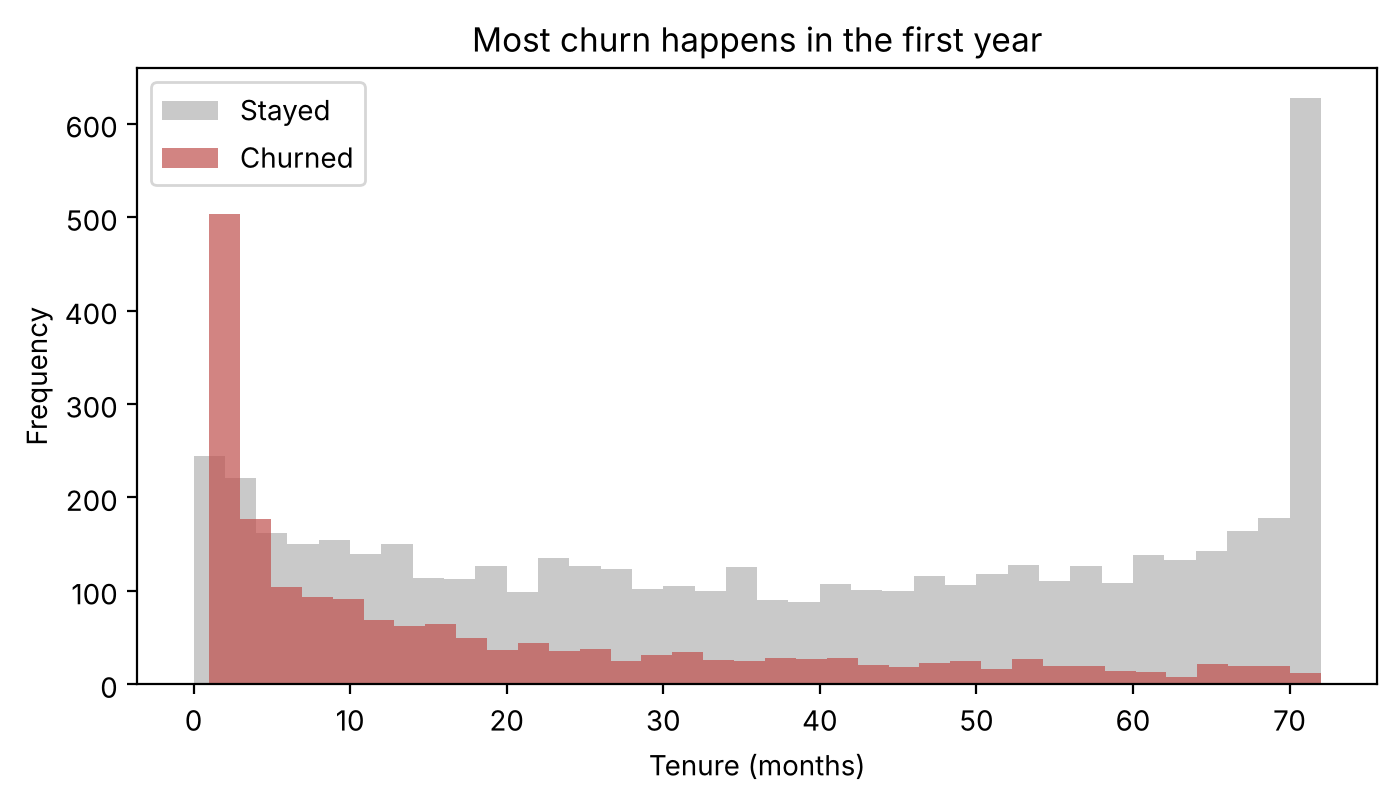

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
df[df.Churned == 0]['tenure'].plot.hist(bins=36, alpha=.6, label='Stayed', ax=ax, color='#A6A6A6')
df[df.Churned == 1]['tenure'].plot.hist(bins=36, alpha=.7, label='Churned', ax=ax, color='#C0504D')
ax.set_xlabel('Tenure (months)'); ax.legend(); ax.set_title('Most churn happens in the first year')
plt.show()

## 3. Model results
Three models were compared with 5-fold cross-validation on the training data only. They score almost the same, so the simplest one (logistic regression) wins: it's easier to explain to a business team and its probabilities are well calibrated.

In [5]:
pd.read_csv('../outputs/model_comparison.csv')

,model,roc_auc,roc_auc_std,brier_score
0,Logistic Regression,0.846,0.012,0.135
1,Random Forest,0.844,0.009,0.136
2,Gradient Boosting,0.842,0.008,0.137


In [6]:
m = json.load(open('../outputs/metrics.json'))
print(f"Decision threshold: {m['decision_threshold']} (tuned on training data, default is 0.5)")
for k in ['roc_auc', 'recall', 'precision', 'f1', 'accuracy']:
    print(f'{k:>10}: {m[k]}')
print('\nAt the default 0.5 threshold:', m['at_default_0.5_threshold'])
print('Simple rule (all month-to-month = churn):', m['baseline_month_to_month_rule'])
print(f"\nTop 20% riskiest customers churn at {m['top20pct_churn_rate']:.0%} vs {m['overall_test_churn_rate']:.0%} overall -> {m['top20pct_lift']}x lift")

Decision threshold: 0.309 (tuned on training data, default is 0.5)
   roc_auc: 0.842
    recall: 0.746
 precision: 0.533
        f1: 0.622
  accuracy: 0.759

At the default 0.5 threshold: {'recall': 0.529, 'precision': 0.664, 'f1': 0.589}
Simple rule (all month-to-month = churn): {'recall': 0.88, 'precision': 0.426, 'f1': 0.574}

Top 20% riskiest customers churn at 66% vs 26% overall -> 2.47x lift


## 4. What drives churn
Permutation importance: shuffle one column and see how much the model's ROC-AUC drops.

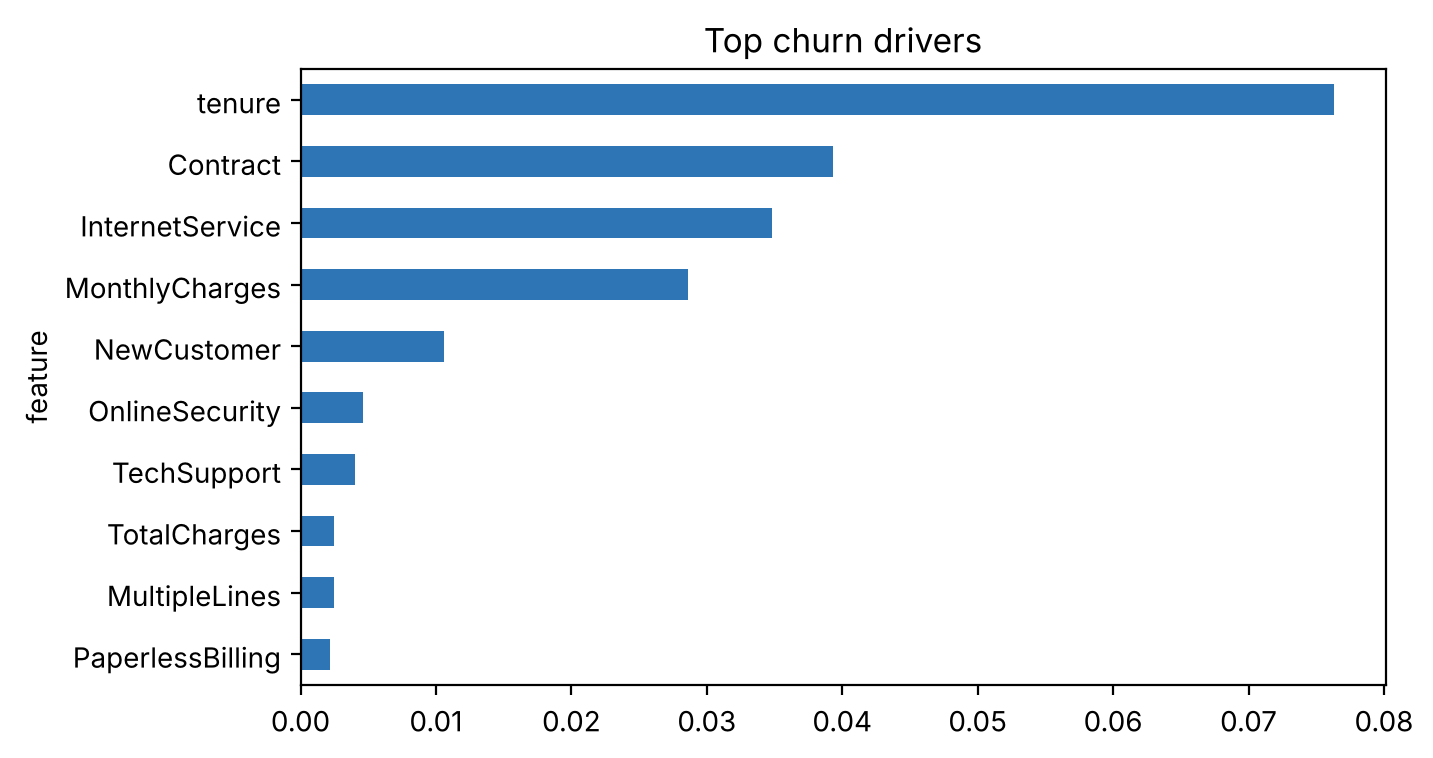

In [7]:
imp = pd.read_csv('../outputs/feature_importance.csv').head(10)
imp.iloc[::-1].plot.barh(x='feature', y='importance', legend=False, color='#2E75B6', figsize=(7, 4))
plt.title('Top churn drivers'); plt.show()

## 5. Who should the retention team call?

In [8]:
scores = pd.read_csv('../outputs/customer_risk_scores.csv')
print(scores['RiskTier'].value_counts())
scores.head(10)

RiskTier
Low       3974
Medium     701
High       499
Name: count, dtype: int64


,customerID,Contract,tenure,InternetService,TechSupport,PaymentMethod,MonthlyCharges,NumAddons,ChurnProbability,RiskTier,MonthlyRevenueAtRisk
0,5150-ITWWB,Month-to-month,3,Fiber optic,No,Electronic check,94.85,2,0.851,High,80.72
1,2545-EBUPK,Month-to-month,2,Fiber optic,No,Electronic check,84.05,1,0.847,High,71.19
2,8161-QYMTT,Month-to-month,7,Fiber optic,No,Electronic check,94.10,2,0.833,High,78.39
3,4847-TAJYI,Month-to-month,6,Fiber optic,No,Electronic check,89.35,2,0.829,High,74.07
4,6969-MVBAI,Month-to-month,9,Fiber optic,No,Electronic check,90.10,2,0.823,High,74.15
5,6350-XFYGW,Month-to-month,4,Fiber optic,No,Electronic check,94.75,3,0.821,High,77.79
6,0187-QSXOE,Month-to-month,7,Fiber optic,No,Electronic check,89.00,2,0.820,High,72.98
7,0021-IKXGC,Month-to-month,1,Fiber optic,No,Electronic check,72.10,0,0.819,High,59.05
8,4115-NZRKS,Month-to-month,7,Fiber optic,No,Electronic check,89.15,2,0.819,High,73.01
9,6630-UJZMY,Month-to-month,4,Fiber optic,No,Electronic check,83.25,1,0.812,High,67.60


## Findings
1. **Contract type is the biggest lever.** Month-to-month customers churn at about 43%, compared with about 3% on two-year contracts.
2. **The first year is the danger zone.** Customers in their first 12 months churn at 48%.
3. **Add-ons build loyalty.** Internet customers with no add-on services churn at 52%; those with all six churn at 5%.
4. **Electronic check payers churn at 45%,** about 3x the rate of autopay customers.
5. **Recommendation:** target new, month-to-month fiber customers with an offer to switch to a 1-year contract plus autopay or a free tech-support add-on. The model's top 20% list concentrates 2.5x more churners than random outreach.